In [1]:
%%bash
pip install -q fairlearn

In [16]:
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country",
    "income"
]

urllib.request.urlretrieve(url, "adult.csv")
df = pd.read_csv("adult.csv", names=columns, sep=r",\s*", engine="python")

df = df.replace('?', np.nan).dropna()
df['income'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
sex = df['sex']

X = df.drop(columns=['income'])
y = df['income']

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex, test_size=0.30, random_state=42, stratify=y
)

X_train_model = X_train.drop(columns=['sex'])
X_test_model = X_test.drop(columns=['sex'])

num_features = X_train_model.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train_model.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model_pipeline.fit(X_train_model, y_train)
y_pred = model_pipeline.predict(X_test_model)
print("Baseline model trained successfully!")

Baseline model trained successfully!


In [17]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference

# 2. MetricFrame Auditing
metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=sex_test
)

print("=== Baseline Part A: Metrics by Group ===")
print(metric_frame.by_group)

# 3. Overall fairness differences and ratios
dp_diff = demographic_parity_difference(y_test, y_pred, sensitive_features=sex_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred, sensitive_features=sex_test)
eo_diff = equalized_odds_difference(y_test, y_pred, sensitive_features=sex_test)

print("\nDemographic parity difference:", round(dp_diff, 4))
print("Demographic parity ratio (DI):", round(dp_ratio, 4))
print("Equalized odds difference:", round(eo_diff, 4))

=== Baseline Part A: Metrics by Group ===
        accuracy  selection_rate       tpr      fpr
sex                                                
Female  0.918072        0.089157  0.530259  0.02932
Male    0.812174        0.258952  0.614698  0.09908

Demographic parity difference: 0.1698
Demographic parity ratio (DI): 0.3443
Equalized odds difference: 0.0844


In [18]:
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import MetricFrame
import pandas as pd

def evaluate_model_predictions(predictions, label):
    mf = MetricFrame(
        metrics=metrics,
        y_true=y_test,
        y_pred=predictions,
        sensitive_features=sex_test
    )
    dp_d = demographic_parity_difference(y_test, predictions, sensitive_features=sex_test)
    eo_d = equalized_odds_difference(y_test, predictions, sensitive_features=sex_test)
    acc = accuracy_score(y_test, predictions)

    sel_m = mf.by_group.loc['Male', 'selection_rate']
    sel_f = mf.by_group.loc['Female', 'selection_rate']

    return {
        'Model': label,
        'ACC': round(acc, 4),
        'SEL_M': round(sel_m, 4),
        'SEL_F': round(sel_f, 4),
        'DP_DIFF': round(dp_d, 4),
        'EO_DIFF': round(eo_d, 4),
        'predictions': predictions
    }

to_dp = ThresholdOptimizer(
    estimator=model_pipeline,
    constraints="demographic_parity",
    predict_method='predict_proba'
)
to_dp.fit(X_train_model, y_train, sensitive_features=sex_train)
y_pred_dp = to_dp.predict(X_test_model, sensitive_features=sex_test)

to_eo = ThresholdOptimizer(
    estimator=model_pipeline,
    constraints="equalized_odds",
    predict_method='predict_proba'
)
to_eo.fit(X_train_model, y_train, sensitive_features=sex_train)
y_pred_eo = to_eo.predict(X_test_model, sensitive_features=sex_test)

results = []
results.append(evaluate_model_predictions(y_pred, "Baseline"))
results.append(evaluate_model_predictions(y_pred_dp, "TO: demographic_par."))
results.append(evaluate_model_predictions(y_pred_eo, "TO: equalized_odds"))

summary_df = pd.DataFrame(results).drop(columns=['predictions'])
print("=== Mitigation Summary Table ===")
print(summary_df.to_string(index=False))

=== Mitigation Summary Table ===
               Model    ACC  SEL_M  SEL_F  DP_DIFF  EO_DIFF
            Baseline 0.8462 0.2590 0.0892   0.1698   0.0844
TO: demographic_par. 0.8301 0.1629 0.1632   0.0002   0.3110
  TO: equalized_odds 0.8314 0.2174 0.1336   0.0839   0.0128


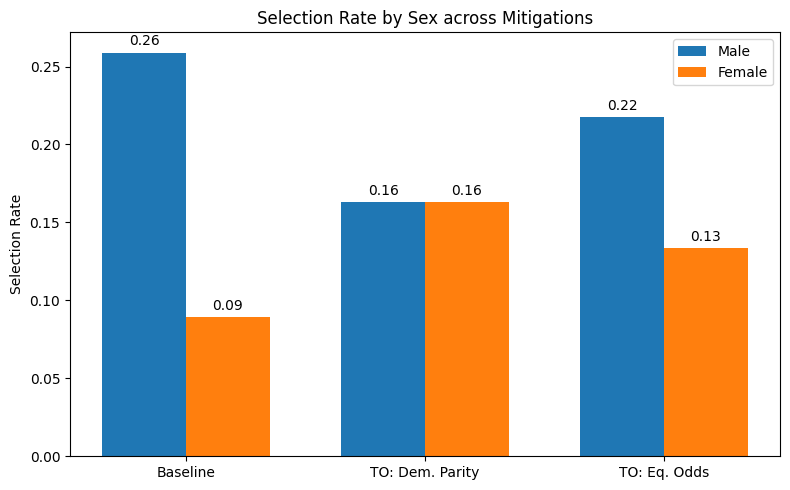

In [19]:
labels = ['Baseline', 'TO: Dem. Parity', 'TO: Eq. Odds']
male_rates = [results[0]['SEL_M'], results[1]['SEL_M'], results[2]['SEL_M']]
female_rates = [results[0]['SEL_F'], results[1]['SEL_F'], results[2]['SEL_F']]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, male_rates, width, label='Male', color='#1f77b4')
rects2 = ax.bar(x + width/2, female_rates, width, label='Female', color='#ff7f0e')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex across Mitigations')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

ax.bar_label(rects1, padding=3, fmt='%.2f')
ax.bar_label(rects2, padding=3, fmt='%.2f')

plt.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()